<a href="https://colab.research.google.com/github/pachterlab/monod/blob/main/demos/monod_walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# *Monod* on Colab

This notebook fits the bursty model with Poisson sequencing noise to five genes in GABAergic and
glutamatergic neurons from one Allen Institute dataset, rejects poorly fitted genes, and tests the fitted
parameters for differences between the two cell types. It installs *Monod* from GitHub and downloads the
example data, so it runs on Colab as it is. `analysis_workflow.ipynb` continues from here (standard errors,
noise decomposition, saving results) and `mek_means.ipynb` covers clustering with meK-Means.

# Inference pipeline

## Install Monod

This installs the pure-Python package. The optional Rust extension (`monod_core`) needs a Rust toolchain and is not built on Colab; everything below runs on the Python code path, just more slowly.

In [ ]:
!git clone -q https://github.com/pachterlab/monod.git
%cd monod
!pip install -q ./
%cd ../

In [ ]:
from monod import extract_data, cme_toolbox, inference, analysis
from monod.inference import search_result_from_uns, searchdata_from_adata
print('monod', __import__('monod').__version__)

## Get the example data

The [monod_examples](https://github.com/pachterlab/monod_examples) repository ships the two AnnData files
as zlib-compressed chunks, together with the poly(A) length reference used for the gene-length correction.

In [4]:
! git clone https://github.com/pachterlab/monod_examples.git
%cd monod_examples
!git checkout anndata
%cd ../

Cloning into 'monod_examples'...


remote: Enumerating objects: 1983, done.


remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (97/97), done.


remote: Total 1983 (delta 72), reused 46 (delta 46), pack-reused 1839 (from 1)
Receiving objects: 100% (1983/1983), 1.31 GiB | 7.40 MiB/s, done.


Resolving deltas: 100% (865/865), done.


Updating files: 100% (120/120), done.


/Users/ConradOakes/monod/monod_examples


branch 'anndata' set up to track 'origin/anndata'.
Switched to a new branch 'anndata'


/Users/ConradOakes/monod


In [ ]:
import zlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import anndata as ad
from IPython.display import display

In [6]:
import logging, sys
logging.basicConfig(stream=sys.stdout)
logging.getLogger('monod').setLevel(logging.INFO)   # progress messages from monod only

import warnings
warnings.filterwarnings('ignore')

In [ ]:
def combine_chunks(input_dir, output_file):
    # The example repository ships each h5ad as zlib-compressed chunks.
    data = b''.join(zlib.decompress(open(f, 'rb').read())
                    for f in sorted(Path(input_dir).glob('chunk_*.gz')))
    open(output_file, 'wb').write(data)

combine_chunks('monod_examples/sample_data/gaba_anndata', 'gaba_example.h5ad')
combine_chunks('monod_examples/sample_data/glu_anndata', 'glu_example.h5ad')
gaba_adata = ad.read_h5ad('gaba_example.h5ad')
glu_adata = ad.read_h5ad('glu_example.h5ad')
print(gaba_adata.shape, glu_adata.shape, list(gaba_adata.layers))

### Filter cells by total counts

In [ ]:
# Knee plot of total counts per cell (monod's helper takes a genes x cells matrix), then drop cells below a threshold.
X = gaba_adata.X.T
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
fig, ax = plt.subplots(figsize=(8, 4))
extract_data.knee_plot(X, ax1=ax, viz=True)
ax.set_xscale('log'); ax.set_title('Knee plot: counts per cell')
plt.show()

threshold = 10
gaba_adata = gaba_adata[np.asarray(gaba_adata.X.sum(axis=1)).ravel() >= threshold].copy()
glu_adata = glu_adata[np.asarray(glu_adata.X.sum(axis=1)).ravel() >= threshold].copy()
print(gaba_adata.n_obs, 'GABAergic and', glu_adata.n_obs, 'glutamatergic cells kept')

## Set up the model and perform inference

`perform_inference` runs the whole pipeline: `extract_data` with the gene-length reference, the scan over the
sampling-parameter grid, the AIC and the standard errors from the Hessian (`exclude_sigma=False`), and writes
everything into `.var` and `.uns` of the returned AnnData. The same five genes are fitted in both datasets so
that their parameters can be compared.

In [ ]:
transcriptome_filepath = './monod_examples/polyA_ref/gg_200524_mouse_genome_polyA_cum_1'
demo_genes = ['Eif5b', 'Xrcc5', 'Klhl12', 'Rgs7', 'Thsd7b']
fitmodel = cme_toolbox.CMEModel('Bursty', 'Poisson')

gaba_adata = inference.perform_inference(gaba_adata, fitmodel, genes_to_fit=demo_genes, n_genes=len(demo_genes),
                                         transcriptome_filepath=transcriptome_filepath, dataset_string='gaba',
                                         exclude_sigma=False)
glu_adata = inference.perform_inference(glu_adata, fitmodel, genes_to_fit=demo_genes, n_genes=len(demo_genes),
                                        transcriptome_filepath=transcriptome_filepath, dataset_string='glu',
                                        exclude_sigma=False)

## Fitted parameters

In [ ]:
# Optimal parameters (log10) with their standard errors, and the AIC per gene.
param_cols = [c for c in gaba_adata.var.columns if '$' in c]
display(gaba_adata.var[['AIC'] + param_cols])
display(glu_adata.var[['AIC'] + param_cols])

# Analysis

## Reject genes.

In [ ]:
# Chi-square goodness-of-fit testing; flags poorly fitted genes in .var and in the stored results.
gaba_adata = inference.reject_genes(gaba_adata, reject_at_bounds=False)
glu_adata = inference.reject_genes(glu_adata, reject_at_bounds=False)

stat_cols = [c for c in gaba_adata.var.columns if 'rejected' in c or 'csq' in c or 'pval' in c or 'hellinger' in c]
display(gaba_adata.var[stat_cols])
display(glu_adata.var[stat_cols])

## Differential expression of the parameters

In [ ]:
# Compare the fitted parameters between the two datasets; fold changes are saved under .var as FC_<parameter>.
DE_genes, DE_filter, offs, residuals = analysis.DE_parameters(glu_adata, gaba_adata, viz=True, use_sigma=True)
display(gaba_adata.var[[c for c in gaba_adata.var.columns if 'FC' in c]])

### Show some gene distributions.

Results are stored in `adata.uns` as plain dictionaries (no pickling). `search_result_from_uns` rebuilds the `SearchResults` object and `searchdata_from_adata` rebuilds the per-gene histograms from the layers; the plotting methods then take both.

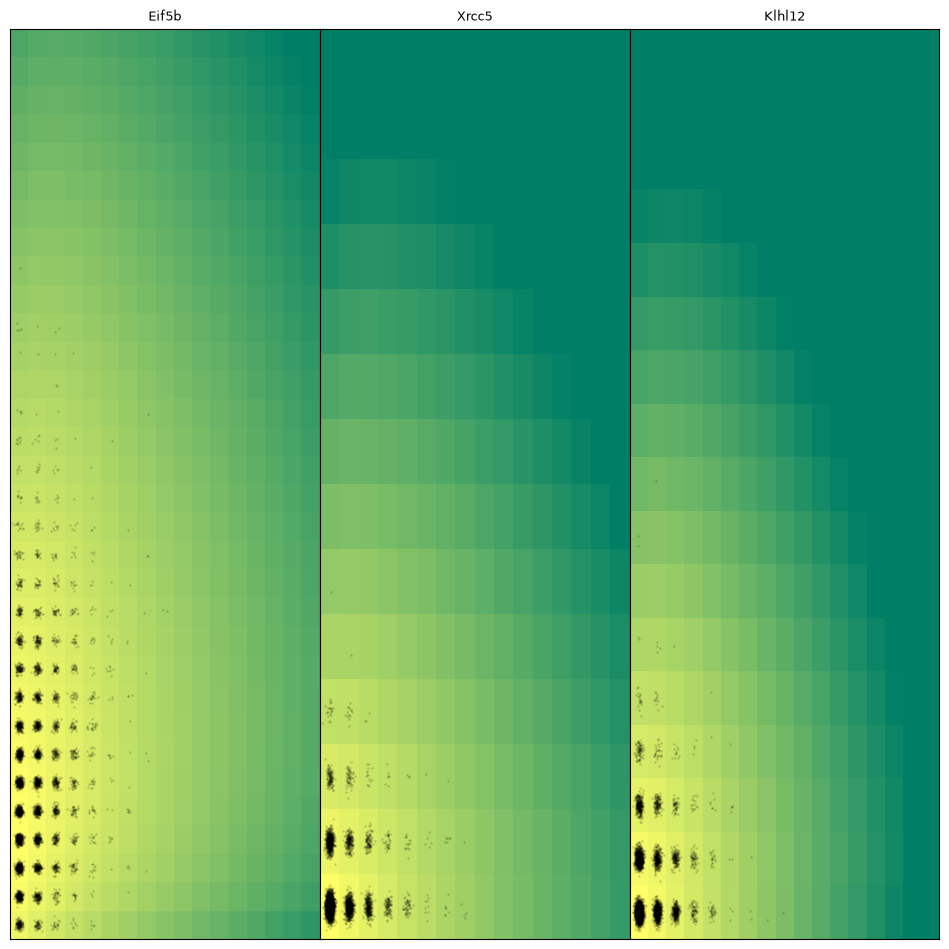

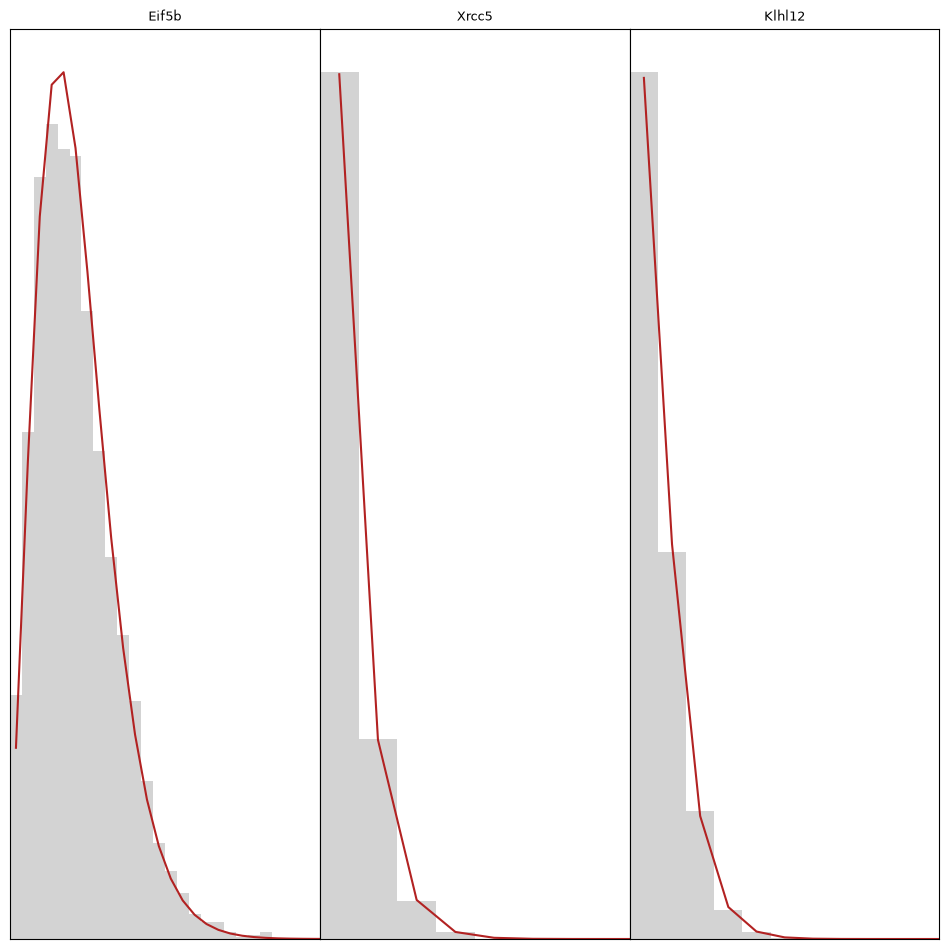

In [22]:
fitted_adata = glu_adata
search_result = search_result_from_uns(fitted_adata.uns['search_result'])
search_data = searchdata_from_adata(fitted_adata)

# Joint (unspliced x spliced) distributions with the fitted model, then the spliced marginals.
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='joint', savefig=False)
search_result.plot_gene_distributions(search_data, sz=(1, 3), marg='spliced', savefig=False)
plt.show()

## Where next

`analysis_workflow.ipynb` continues with standard errors, noise decomposition and saving the fitted AnnData;
`sequencing_noise.ipynb` explains the Poisson sequencing model and the gene-length correction used here;
`mek_means.ipynb` clusters cells with meK-Means instead of fitting one population.